<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/LSMT_implementation/GAN_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##LSTM Implementation

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
from jax import random

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from sklearn.preprocessing import MinMaxScaler

In [3]:
print(jax.devices())

[CudaDevice(id=0)]


In [4]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [5]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [6]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels], df_company[close_data]

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [8]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [9]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

dataset = MyDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

In [10]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [11]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

### **Implementazione jit-friendly**

In [12]:
chosen_loss = mse_loss

In [13]:
import jax
import jax.numpy as jnp
from jax import jit, vmap, lax, grad
from jax.nn import sigmoid

# ---------- FUNZIONI PURE ----------
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq[-1]  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

# ---------- VERSIONI JITTATE ----------
forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])


# ---------- WRAPPER ----------
class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    # ---- Metodi wrapper ----
    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


In [14]:
# hyperparameters
input_size = 5
# hidden size = 48
hidden_size = 48
num_epochs = 500
# lr = 0.055
# seq_len = 5
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

In [15]:
from datetime import datetime
import jax
import jax.numpy as jnp
from jax import jit, grad

# ---------- TRAIN STEP JITTATO ----------
def train_step(params, X_batch, Y_batch, lr, model, loss_function):
    """
    Esegue un passo di training su un batch jittato.
    """
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        #return jnp.mean((Y_pred - Y_batch) ** 2)  # MSE, puoi sostituire con loss personalizzata
        return loss_function(Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames=['model', 'loss_function'])

# ---------- TRAIN LOOP ----------
def train_LSTM(model, X_train, y_train, seq_len, loss_function, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop per la LSTM con batch jittato.
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, seq_len, output_size)
    """
    # Crea dataset e loader
    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Converti batch in JAX arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Aggiorna parametri con train_step jittato
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model, loss_function)

            # Loss del batch per monitoraggio
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = loss_function(Y_pred, Y_batch)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)

        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [16]:
losses = train_LSTM(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

/tmp/ipython-input-3842568575.py:17: DeprecationWarning: jax.tree_map is deprecated: use jax.tree.map (jax v0.4.25 or newer) or jax.tree_util.tree_map (any JAX version).
  new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)


Epoch [50/500], Loss: 0.005278 [2025-08-21 14:18:56.844878]
Epoch [100/500], Loss: 0.004394 [2025-08-21 14:19:03.896012]
Epoch [150/500], Loss: 0.003976 [2025-08-21 14:19:08.800062]
Epoch [200/500], Loss: 0.003664 [2025-08-21 14:19:14.962510]
Epoch [250/500], Loss: 0.003687 [2025-08-21 14:19:19.672235]
Epoch [300/500], Loss: 0.003309 [2025-08-21 14:19:24.851077]
Epoch [350/500], Loss: 0.003309 [2025-08-21 14:19:30.839627]
Epoch [400/500], Loss: 0.003464 [2025-08-21 14:19:37.045055]
Epoch [450/500], Loss: 0.003173 [2025-08-21 14:19:43.279164]
Epoch [500/500], Loss: 0.003151 [2025-08-21 14:19:48.116566]


In [17]:
def test_LSTM(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = loss_function(Y_pred, Y_batch)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [18]:
preds, actuals = test_LSTM(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)

Test Loss: 0.0072


In [19]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

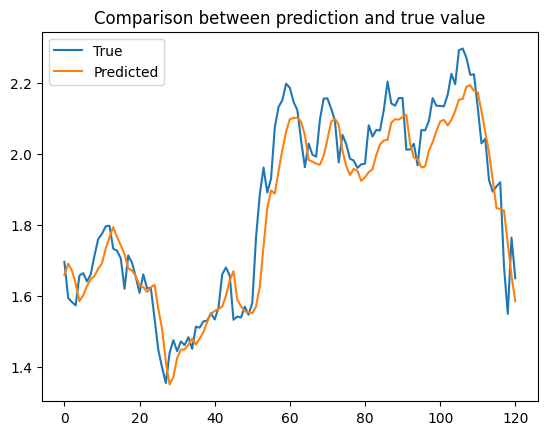

In [20]:
plot_predictions(preds, actuals)

## **Discriminator and Generator**

In [73]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.

      Cose da notare / considerare:
        - Dato che stiamo usando un MLP, vuoi un input a forma di vettore, però nel paper viene usato un input che prevede più samples.
          In particolare costruisce una matrice X formata da (t + 1) time steps (presi dai dati reali).
          I primi t valori saranno presi dal dattaset, mentre l'ultimo verrà o generato dal generatore, oppure preso anch'esso dal dataset reale.

        - A seguito di quanto detto nel punto prima, sarà anche da considerare l'ampiezza dell'intervallo di time steps come hyperparameter.

        - Andrà anche considerato che nel nostrto dataset, non abbiamo un dato per ogni giorno specifico.
          Potrebbe essere sensato kl non considare questo aspetto poichè alla fine non poniamo le date come un input utile.
          Se volessimo però avere una predizione che considera la data, cioè vogliamo considerare anche che c'è una dipendenza dagli effetivi giorni che separano un sample al tempo t e al tempo t+1,
            dovremmo intervenire in qualche modo.
          (da notare che attualmente le moving average non tengono conto di questo)

        - Come gestiamo la differenza dimensionale tra gli input?
          Soluzione 1: Usiamo un reshape che rende unidimensionale la matrice concatenando un sample dietro l'altro
  '''

  '''
    seq_len: la sequence size
    t_features: è il numero di features per ogni sample.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability. <---
    # After the first, second, and third hidden layers, you use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # You use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model you’ve defined without any other processing.

  def forward(self, x):
    # x shape attesa: (batch_size, t_input, n_features)
    # Flatten temporale e feature dimensioni → (batch_size, t_input * n_features)
    # print(f"From discriminator (input_shape): {x.shape}")
    X_flat = x.view(x.size(0), -1)
    # print(f"From discriminator (X_flat_shape): {X_flat.shape}")
    return self.model(X_flat)

In [74]:
# ---------- FUNZIONI PURE ----------
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq  # (seq_len,output_size)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

# ---------- VERSIONI JITTATE ----------
forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])



In [75]:
class GeneratorLSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    # ---- Metodi wrapper ----
    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)

## **Training**

In [76]:
from torch.utils.data import Dataset

class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [77]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

datasetGAN = MyGANDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(datasetGAN, batch_size=32, shuffle=False)

In [78]:
# per debug, lascio questa stampa dei batch creati automaticamente dal dataloader
for i, (x_batch, y_batch) in enumerate(loader):
    print(f"Batch {i+1}: {x_batch.size}")
    print("x_batch shape:", x_batch.shape)
    print("y_batch shape:", y_batch.shape)
    print("-" * 30)
    if i == 0:
        break

Batch 1: <built-in method size of Tensor object at 0x7eb26c55e3a0>
x_batch shape: torch.Size([32, 10, 5])
y_batch shape: torch.Size([32, 10, 1])
------------------------------


In [79]:
def get_fake_labels(real_labels, output_LSTM):
    # real_labels (batch_size, seq_len, 1)
    # output_LSTM (batch_size, seq_len, 1)

    last_step_output = output_LSTM[:, -1, :]  # (batch_size, 1)

    y_fake = jnp.array(real_labels, dtype=jnp.float32)
    y_fake = y_fake.at[:, -1, :].set(last_step_output)
    return torch.tensor(np.array(y_fake), dtype=torch.float32)

In [80]:
key = random.PRNGKey(0)
generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

x_batch, y_batch = next(iter(loader))
X_batch = jnp.array(x_batch, dtype=jnp.float32)

outputs = generator.forward_batch(generator.params, X_batch)
print(outputs.shape)

(32, 10, 1)


In [81]:
y_batch[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [-1.5127]])

In [82]:
get_fake_labels(y_batch, outputs)[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [ 0.0822]])

In [141]:
import torch.nn.functional as F

def discriminator_loss(D_real, D_fake):
    # Small epsilon to prevent log(0)
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss_val = mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = jnp.mean(jnp.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss_val + lambda2 * adv_loss

In [160]:
def train_step_generator(params, X_batch, Y_batch, lr, model, generator_loss, D_out):
    """
    Esegue un passo di training su un batch jittato.
    """
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        #return jnp.mean((Y_pred - Y_batch) ** 2)  # MSE, puoi sostituire con loss personalizzata
        return generator_loss(D_out, Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_generator_jit = jax.jit(train_step_generator, static_argnames=['model', 'generator_loss'])



def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=False)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  for epoch in range(epochs):
    for i, (x_real, y_real) in enumerate(loader):

      # print(f"y_real shape: {y_real.shape}")
      X_batch = jnp.array(x_real, dtype=jnp.float32)
      Y_batch = jnp.array(y_real, dtype=jnp.float32)
      output_LSTM = generator.forward_batch(generator.params, X_batch)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # print(f"y-fake shape: {y_fake.shape}")

      # Training the discriminator
      discriminator.zero_grad() # In PyTorch, it’s necessary to clear the gradients at each training step to avoid accumulating them. You do this using .zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      # You calculate the gradients to update the weights with loss_discriminator.backward()
      loss_discriminator.backward()
      # You update the discriminator weights by calling optimizer_discriminator.step()
      discriminator_optimizer.step()

      # Training the generator ---------------------------------------------------------------------------------------------------------------------


      # Loss del batch per monitoraggio
      output_LSTM = generator.forward_batch(generator.params, X_batch)

      Y_fake = get_fake_labels(Y_batch, output_LSTM)

      output_discriminator_generated = discriminator(Y_fake)

      # You calculate the loss function using the output of the classification system stored in output_discriminator_generated and the labels in real_samples_labels, which are all equal to 1.
      D_output_array = jnp.array(output_discriminator_generated.detach().cpu().numpy(), dtype=jnp.float32)
      loss_generator = generator_loss(
        D_output_array, output_LSTM, Y_batch
      )

      G_losses.append(loss_generator.item())

      generator.params = train_step_generator_jit(generator.params, X_batch, Y_batch, learning_rate_generator, generator, generator_loss, D_output_array)

    # Show loss
    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [171]:
# hyperparameters
input_size = 5
hidden_size = 48
num_layers = 1
num_epochs = 500
lr_D = 0.005
lr_G =0.055
seq_len = 5

generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)
discriminator = Discriminator(seq_len)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr_D)

In [172]:
discriminator_losses, generator_losses = train_GAN(
    generator,
    discriminator,
    lr_D,
    lr_G,
    num_epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len)

Epoch: 0 Loss D.: 1.347832202911377
Epoch: 0 Loss G.: 0.0438670814037323
Epoch: 50 Loss D.: 1.3712077140808105
Epoch: 50 Loss G.: -0.19389189779758453
Epoch: 100 Loss D.: 1.9219361543655396
Epoch: 100 Loss G.: -0.24323917925357819
Epoch: 150 Loss D.: 1.4406486749649048
Epoch: 150 Loss G.: -0.19817779958248138
Epoch: 200 Loss D.: 1.340233325958252
Epoch: 200 Loss G.: -0.1826373189687729
Epoch: 250 Loss D.: 1.3835225105285645
Epoch: 250 Loss G.: -0.1894761323928833
Epoch: 300 Loss D.: 1.4156363010406494
Epoch: 300 Loss G.: -0.20153245329856873
Epoch: 350 Loss D.: 1.3798048496246338
Epoch: 350 Loss G.: -0.19358517229557037
Epoch: 400 Loss D.: 1.3512085676193237
Epoch: 400 Loss G.: -0.2013469785451889
Epoch: 450 Loss D.: 1.3798327445983887
Epoch: 450 Loss G.: -0.19445140659809113


In [173]:
def test_GAN(model, seq_len, loss_function):
  #model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      X_batch = jnp.array(x_batch, dtype=jnp.float32)
      Y_batch = jnp.array(y_batch, dtype=jnp.float32)
      outputs = model.forward_batch(model.params, X_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = Y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss * X_batch.shape[0]

      preds.extend(last_step_output)
      actuals.extend(last_step_label)

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [174]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, chosen_loss)

Test Loss: 0.0020


In [175]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

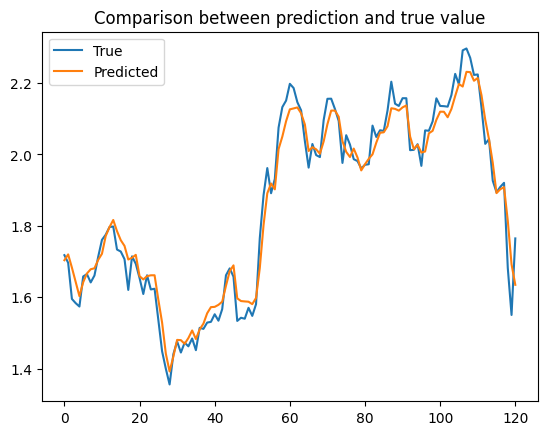

In [176]:
plot_predictions(preds_GAN, actuals_GAN)

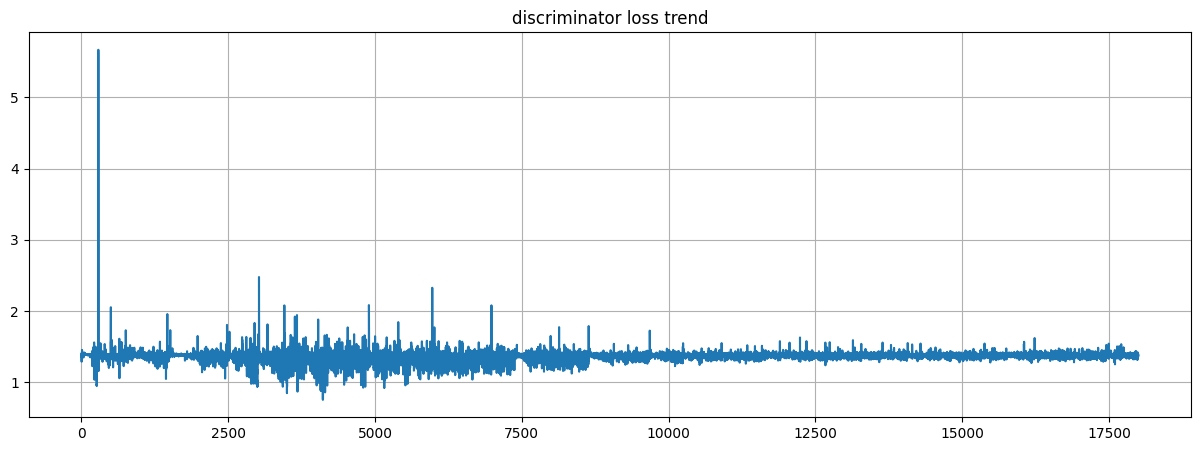

In [177]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("discriminator loss trend")


plt.grid(True)


plt.show()

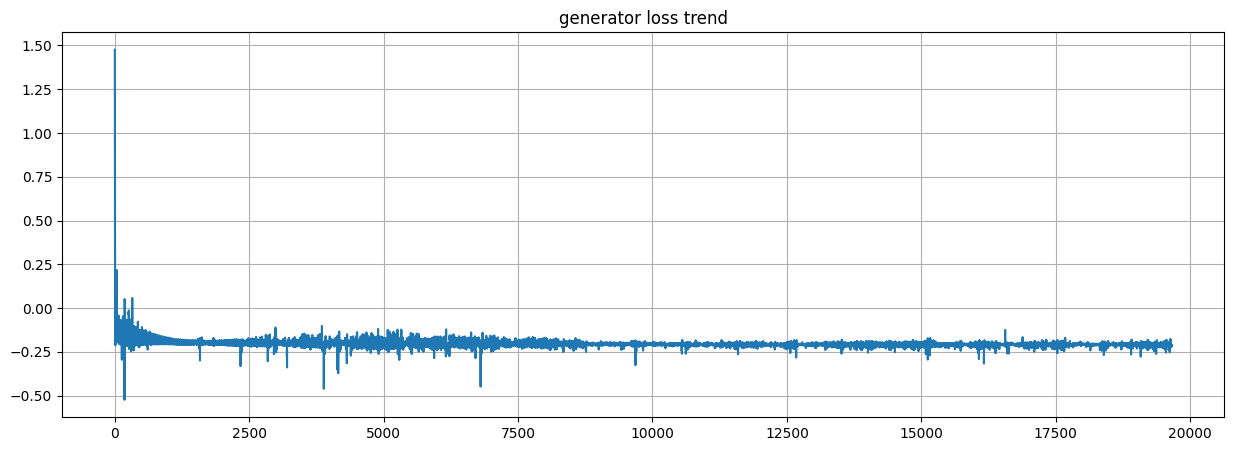

In [168]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("generator loss trend")


plt.grid(True)


plt.show()